In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Dataset loaded successfully!")
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


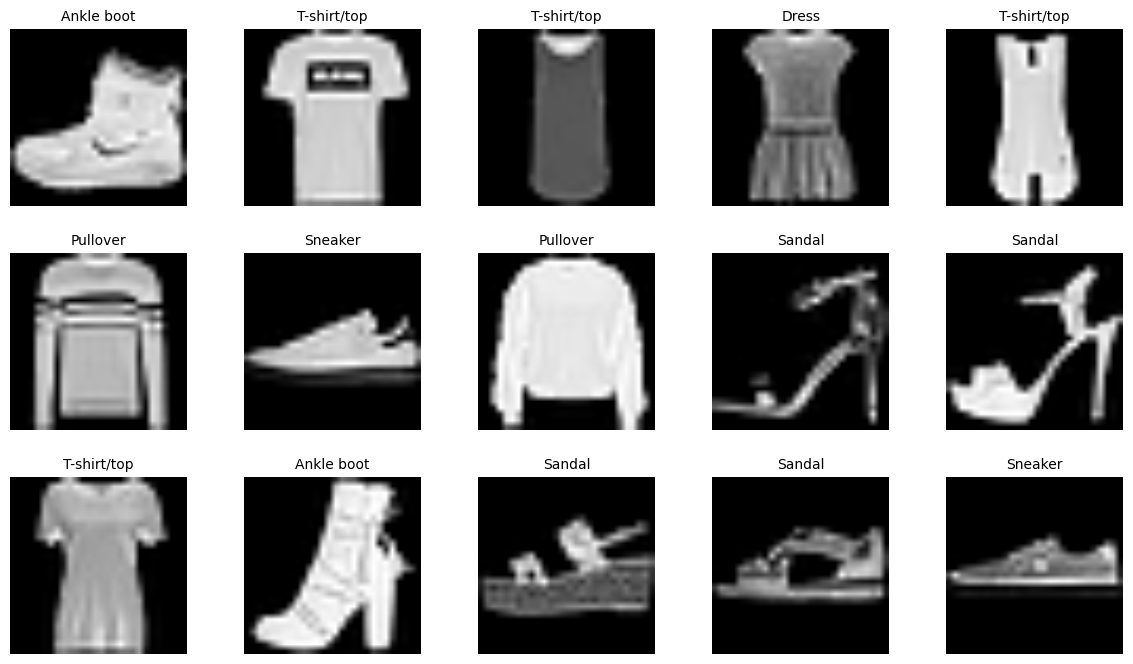

In [17]:
plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(
        x_train[i],
        cmap="gray",
        interpolation="bilinear",
        vmin=0,
        vmax=1
    )
    plt.title(class_names[y_train[i]], fontsize=10)
    plt.axis("off")

plt.tight_layout(pad=2)
plt.show()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training data minimum:", x_train.min())
print("Training data maximum:", x_train.max())
print("Testing data minimum:", x_test.min())
print("Testing data maximum:", x_test.max())
print("Data preprocessing completed successfully.")

Training data minimum: 0.0
Training data maximum: 1.0
Testing data minimum: 0.0
Testing data maximum: 1.0
Data preprocessing completed successfully.


In [5]:
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.7993 - loss: 0.5713 - val_accuracy: 0.8472 - val_loss: 0.4197
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8514 - loss: 0.4102 - val_accuracy: 0.8670 - val_loss: 0.3694
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8644 - loss: 0.3711 - val_accuracy: 0.8635 - val_loss: 0.3700
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8696 - loss: 0.3519 - val_accuracy: 0.8708 - val_loss: 0.3550
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8775 - loss: 0.3344 - val_accuracy: 0.8772 - val_loss: 0.3371
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8811 - loss: 0.3203 - val_accuracy: 0.8777 - val_loss: 0.3399
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8836 - loss: 0.3106 - val_accuracy: 0.8777 - val_loss: 0.3343
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8878 - loss: 0.2999 - val_accuracy: 0.

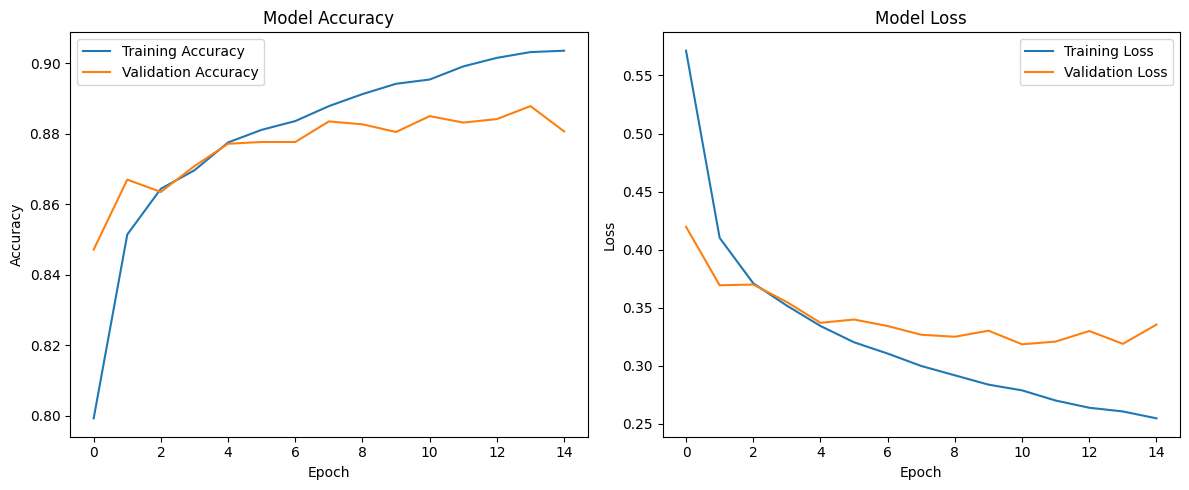

In [7]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

precision = tf.keras.metrics.Precision()
recall = tf.keras.metrics.Recall()

precision.update_state(
    tf.one_hot(y_test, 10),
    y_prob
)

recall.update_state(
    tf.one_hot(y_test, 10),
    y_prob
)

f1_score = 2 * precision.result().numpy() * recall.result().numpy() / (
    precision.result().numpy() + recall.result().numpy() + 1e-8
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Precision:", round(precision.result().numpy(), 4))
print("Recall:", round(recall.result().numpy(), 4))
print("F1-Score:", round(f1_score, 4))

Test Loss: 0.3578
Test Accuracy: 87.83 %
Precision: 0.8923
Recall: 0.8662
F1-Score: 0.8791


In [9]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

 T-shirt/top     0.7918    0.8860    0.8362      1000
     Trouser     0.9898    0.9680    0.9788      1000
    Pullover     0.8401    0.7200    0.7754      1000
       Dress     0.8353    0.9130    0.8724      1000
        Coat     0.7375    0.8710    0.7987      1000
      Sandal     0.9708    0.9640    0.9674      1000
       Shirt     0.7586    0.5940    0.6663      1000
     Sneaker     0.9123    0.9670    0.9388      1000
         Bag     0.9838    0.9700    0.9768      1000
  Ankle boot     0.9789    0.9300    0.9538      1000

    accuracy                         0.8783     10000
   macro avg     0.8799    0.8783    0.8765     10000
weighted avg     0.8799    0.8783    0.8765     10000



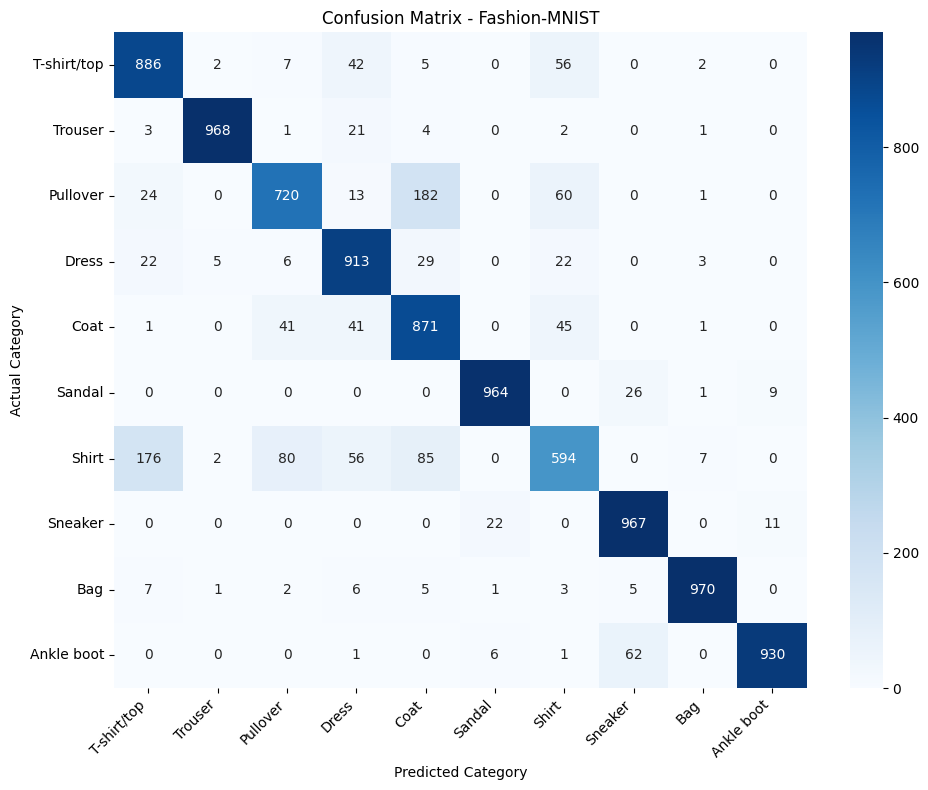

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Fashion-MNIST")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

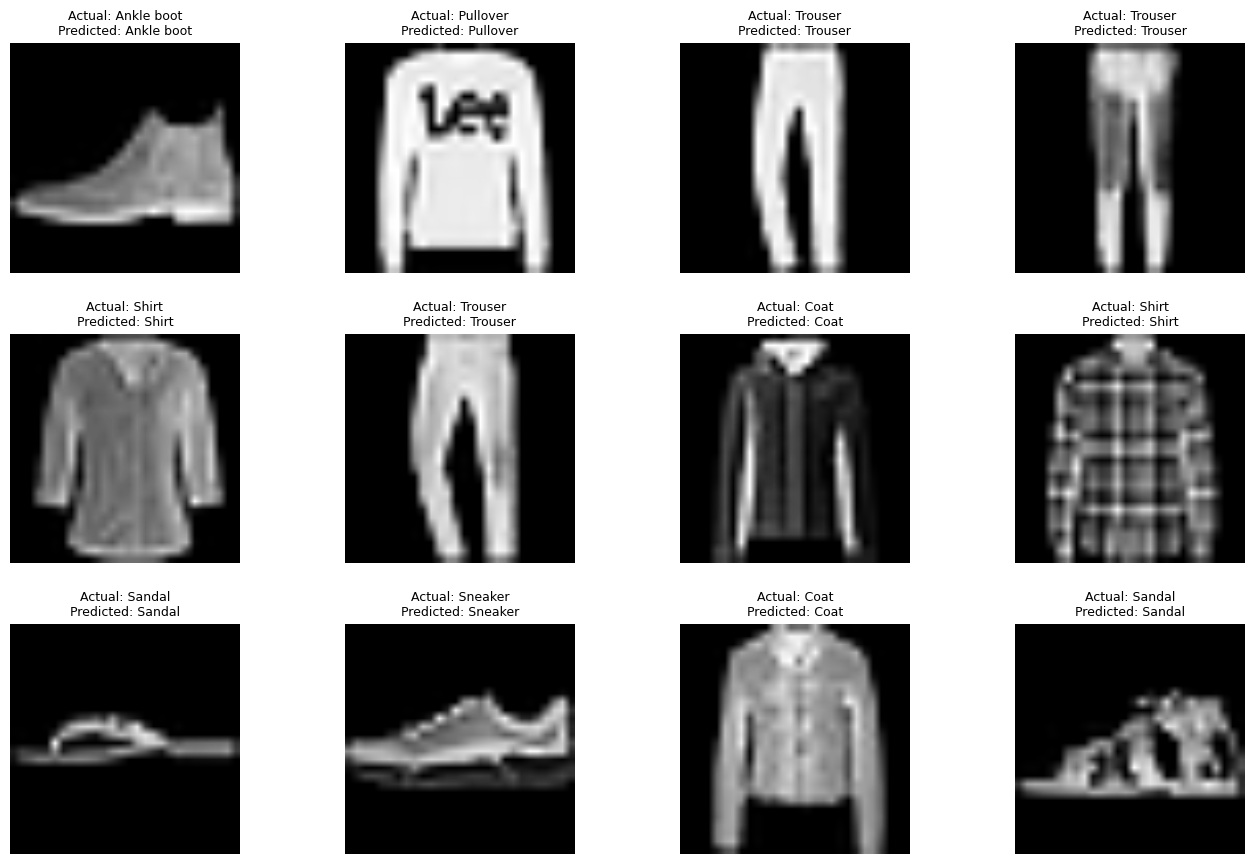

In [20]:
plt.figure(figsize=(14, 9))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(
        x_test[i],
        cmap="gray",
        interpolation="bilinear",
        vmin=0,
        vmax=1
    )

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout(pad=2)
plt.show()

In [14]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

metrics_df = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Value": [
        float(test_loss),
        float(test_accuracy),
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0)
    ]
})

predictions_df = pd.DataFrame({
    "Actual Category": np.array(class_names)[y_test],
    "Predicted Category": np.array(class_names)[y_pred]
})

metrics_df.to_csv("Week5_Model_Evaluation_Metrics.csv", index=False)
predictions_df.to_csv("Week5_Fashion_MNIST_Predictions.csv", index=False)

print(metrics_df.to_string(index=False))
print("\nBoth CSV files have been saved successfully.")

            Metric    Value
         Test Loss 0.357805
     Test Accuracy 0.878300
Weighted Precision 0.879892
   Weighted Recall 0.878300
 Weighted F1-Score 0.876480

Both CSV files have been saved successfully.


In [15]:
from google.colab import files

files.download("Week5_Model_Evaluation_Metrics.csv")
files.download("Week5_Fashion_MNIST_Predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
check_loss, check_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

probabilities = model.predict(x_test, verbose=0)

manual_loss = np.mean(
    tf.keras.losses.sparse_categorical_crossentropy(
        y_test, probabilities
    ).numpy()
)

print("Test loss from model:", check_loss)
print("Test loss calculated separately:", manual_loss)
print("Test accuracy:", round(check_accuracy * 100, 2), "%")
print("Prediction probability sums:", probabilities[:5].sum(axis=1))

Test loss from model: 0.3578052520751953
Test loss calculated separately: 0.35625333
Test accuracy: 87.83 %
Prediction probability sums: [1.         1.         0.99999994 0.99999994 1.        ]
